# SafeScan Model V1

Trains and compares **XGBoost** and **Random Forest** to score a receiver as Safe, Caution or Risky before a payment is made. This is the model behind the FastAPI inference service.

Steps: load and inspect, clean, explore, split by receiver, train, evaluate, compare, build risk bands, save the models.


## 1. Setup

Importing the libraries and set the global options.

In [1]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

RANDOM_STATE = 42
DATA_PATH = "training_clean.csv"

## 2. Load and inspect

Read the CSV and look at its shape, column types and first rows.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["created_at"])
print("Shape:", df.shape)
df.info()
df.head()

Shape: (1809, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1809 entries, 0 to 1808
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   receiver_id             1809 non-null   object        
 1   created_at              1809 non-null   datetime64[ns]
 2   receiver_age_days       1809 non-null   int64         
 3   txn_count_24h           1809 non-null   int64         
 4   txn_count_7d            1809 non-null   int64         
 5   unique_senders_24h      1809 non-null   int64         
 6   scan_count_24h          1809 non-null   int64         
 7   spam_report_count       1809 non-null   int64         
 8   block_rate              1809 non-null   float64       
 9   avg_transaction_amount  1809 non-null   float64       
 10  hour_of_day             1809 non-null   int64         
 11  target_is_risky         1809 non-null   bool          
dtypes: bool(1), datetime64[ns](1),

,receiver_id,created_at,receiver_age_days,txn_count_24h,txn_count_7d,unique_senders_24h,scan_count_24h,spam_report_count,block_rate,avg_transaction_amount,hour_of_day,target_is_risky
0,8ff07ea7-295f-4f56-87d5-57a074e839d0,2026-05-25 09:07:37,0,0,0,0,0,0,0.0,0.0,14,False
1,d969f90d-aa10-4b0c-98b9-ba772a392d1b,2026-05-25 10:49:11,0,0,0,0,0,0,0.0,0.0,16,False
2,cbc7d75e-5249-4d01-bc14-940d7e9424ac,2026-05-27 08:40:49,0,0,0,0,0,0,0.0,0.0,14,False
3,55d2d633-c65c-449a-ac0c-8614c8ed64f5,2026-05-29 07:25:45,0,0,0,0,0,0,0.0,0.0,12,False
4,ae9ef5bc-97c2-4b36-b412-e96b648e53e1,2026-05-29 11:23:34,0,0,0,0,0,0,0.0,0.0,16,False


Check for missing values, duplicate rows and basic statistics. Also count how many distinct receivers there are, because several rows can belong to the same receiver.

In [3]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("Distinct receivers:", df["receiver_id"].nunique())
print("Rows per receiver:")
print(df.groupby("receiver_id").size().describe().round(1).to_string())
print("\nDate range:", df["created_at"].min(), "to", df["created_at"].max())
df.describe().T.round(2)

Missing values per column:
receiver_id               0
created_at                0
receiver_age_days         0
txn_count_24h             0
txn_count_7d              0
unique_senders_24h        0
scan_count_24h            0
spam_report_count         0
block_rate                0
avg_transaction_amount    0
hour_of_day               0
target_is_risky           0

Duplicate rows: 0
Distinct receivers: 307
Rows per receiver:
count    307.0
mean       5.9
std        3.7
min        1.0
25%        2.0
50%        6.0
75%       10.0
max       10.0

Date range: 2026-05-25 09:07:37 to 2026-09-14 14:25:41


,count,mean,min,25%,50%,75%,max,std
created_at,1809,2026-08-04 21:57:16.900497664,2026-05-25 09:07:37,2026-07-13 05:41:38,2026-08-09 07:58:49,2026-08-29 08:03:18,2026-09-14 14:25:41,NaN
receiver_age_days,1809.0,16.347706,0.0,0.0,5.0,26.0,108.0,22.541558
txn_count_24h,1809.0,0.301271,0.0,0.0,0.0,0.0,5.0,0.702716
txn_count_7d,1809.0,1.08126,0.0,0.0,0.0,2.0,12.0,1.593865
unique_senders_24h,1809.0,0.298507,0.0,0.0,0.0,0.0,5.0,0.693206
scan_count_24h,1809.0,2.083472,0.0,0.0,0.0,2.0,36.0,4.45655
spam_report_count,1809.0,0.228856,0.0,0.0,0.0,0.0,5.0,0.61384
block_rate,1809.0,44.019823,0.0,0.0,40.0,83.33,100.0,37.410104
avg_transaction_amount,1809.0,604.640426,0.0,0.0,280.0,705.0,12166.67,1027.315952
hour_of_day,1809.0,14.698729,0.0,11.0,16.0,19.0,23.0,5.554079


## 3. Clean the data

Remove duplicates, convert the target to 0 and 1, and drop rows that break basic rules (negative counts, block rate outside 0 to 100, hour outside 0 to 23). Large transaction amounts are kept because tree models handle them well and they can be real signals.

In [4]:
FEATURES = [
    "receiver_age_days", "txn_count_24h", "txn_count_7d", "unique_senders_24h",
    "scan_count_24h", "spam_report_count", "block_rate",
    "avg_transaction_amount", "hour_of_day",
]
TARGET = "target_is_risky"

rows_before = len(df)
df = df.drop_duplicates().copy()
df[TARGET] = df[TARGET].astype(int)

non_negative = [c for c in FEATURES if c not in ("hour_of_day", "block_rate")]
valid = (df[non_negative] >= 0).all(axis=1)
valid &= df["block_rate"].between(0, 100)
valid &= df["hour_of_day"].between(0, 23)
df = df[valid].sort_values("created_at").reset_index(drop=True)

print(f"Rows before: {rows_before}, after: {len(df)}, removed: {rows_before - len(df)}")
print("7 day count smaller than 24 hour count:", int((df["txn_count_7d"] < df["txn_count_24h"]).sum()), "rows")

Rows before: 1809, after: 1809, removed: 0
7 day count smaller than 24 hour count: 0 rows


## 4. Explore the data

First, the class balance, and how the risky rate changes with the number of spam reports.

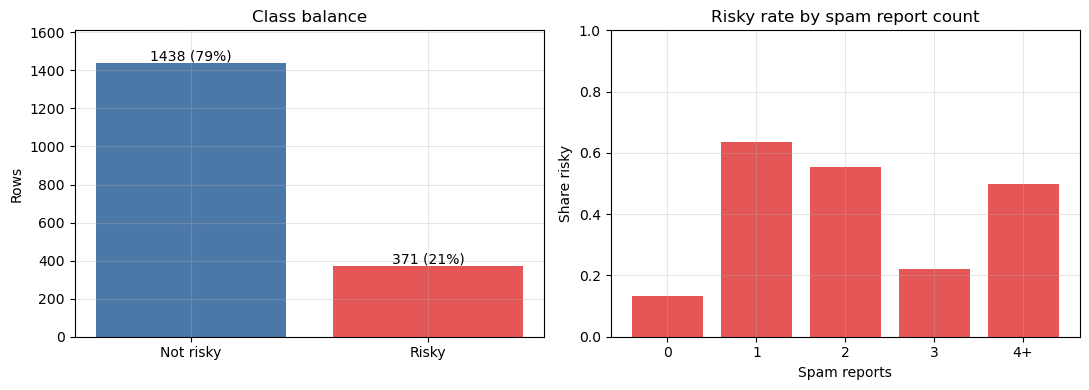

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df[TARGET].value_counts().sort_index()
axes[0].bar(["Not risky", "Risky"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v} ({v / len(df):.0%})", ha="center", va="bottom")
axes[0].set_title("Class balance")
axes[0].set_ylim(0, counts.max() * 1.12)
axes[0].set_ylabel("Rows")

spam_rate = df.groupby(df["spam_report_count"].clip(upper=4))[TARGET].mean()
axes[1].bar([str(i) if i < 4 else "4+" for i in spam_rate.index], spam_rate.values, color="#E45756")
axes[1].set_title("Risky rate by spam report count")
axes[1].set_xlabel("Spam reports")
axes[1].set_ylabel("Share risky")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

Compare the distribution of every feature for risky and not risky receivers. Features where the two shapes differ are the useful ones.

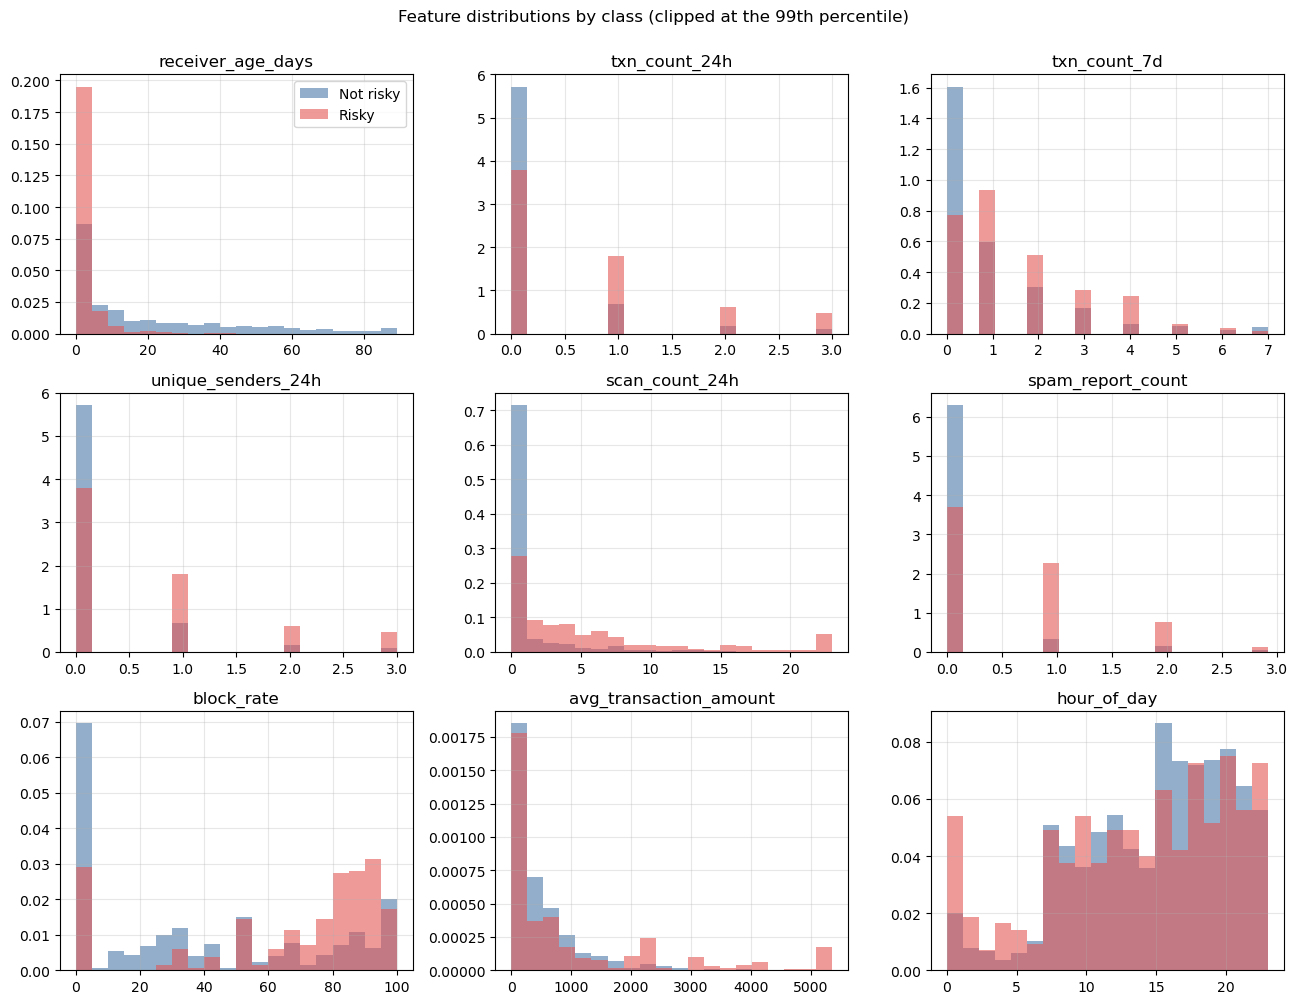

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.ravel(), FEATURES):
    upper = df[col].quantile(0.99)
    data = df[col].clip(upper=upper)
    bins = np.histogram_bin_edges(data, bins=20)
    ax.hist(data[df[TARGET] == 0], bins=bins, alpha=0.6, density=True, label="Not risky", color="#4C78A8")
    ax.hist(data[df[TARGET] == 1], bins=bins, alpha=0.6, density=True, label="Risky", color="#E45756")
    ax.set_title(col)
axes[0, 0].legend()
fig.suptitle("Feature distributions by class (clipped at the 99th percentile)", y=1.0)
plt.tight_layout()
plt.show()

A correlation heatmap shows which features move together and which relate most to the target.

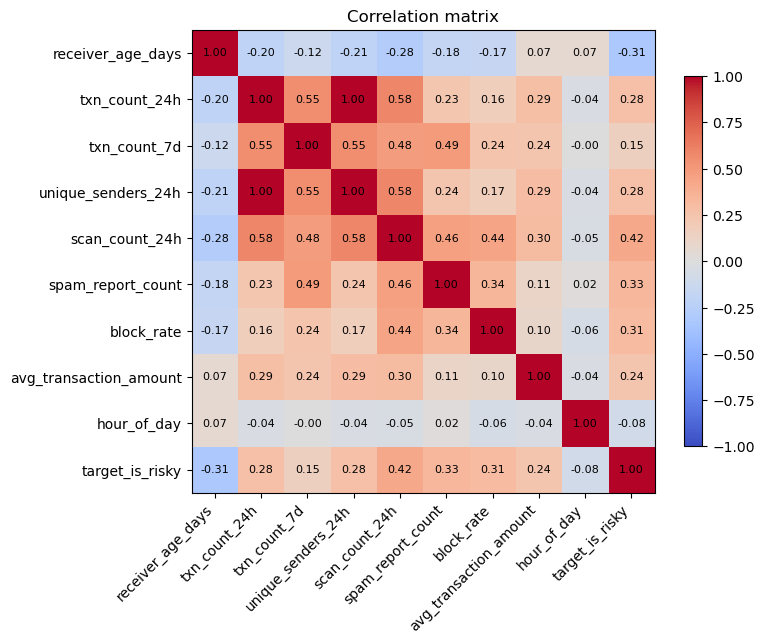

Correlation with target:
scan_count_24h            0.417
spam_report_count         0.330
block_rate                0.305
unique_senders_24h        0.281
txn_count_24h             0.279
avg_transaction_amount    0.235
txn_count_7d              0.150
hour_of_day              -0.080
receiver_age_days        -0.313


In [7]:
corr = df[FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

## 5. Split by receiver

The same receiver appears in many rows. If rows are split randomly, one receiver can land in both train and test and the score looks better than it really is. The strategic summary calls this out, so the split here keeps all rows of a receiver together using `receiver_id` as the group.

In [8]:
per_receiver = df.groupby("receiver_id")[TARGET].agg(["mean", "size"])
mixed = ((per_receiver["mean"] > 0) & (per_receiver["mean"] < 1)).sum()
print(f"Receivers: {len(per_receiver)}, receivers whose rows have mixed labels: {mixed}")

X = df[FEATURES]
y = df[TARGET]
groups = df["receiver_id"]

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Risky share, train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))
print("Receivers shared between train and test:", len(set(g_train) & set(groups.iloc[test_idx])))

# Cross validation folds for tuning, also grouped by receiver
cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                .split(X_train, y_train, g_train))

Receivers: 307, receivers whose rows have mixed labels: 1
Train rows: 1444 | Test rows: 365
Risky share, train: 0.209 | test: 0.189
Receivers shared between train and test: 0


## 6. Baselines

Any model has to beat something simple. A one line rule (flag a receiver with at least one spam report) and a Logistic Regression give the reference points.

The helper below computes the same metrics for every model. PR-AUC is the most useful number here because risky receivers are the minority.

In [9]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }


probas = {}   # test set probabilities for every model
results = []  # one metrics row per model

# Rule baseline
probas["Rule: spam >= 1"] = (X_test["spam_report_count"] >= 1).astype(float).values

# Logistic Regression baseline
log_reg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
log_reg.fit(X_train, y_train)
probas["Logistic Regression"] = log_reg.predict_proba(X_test)[:, 1]

for name in ["Rule: spam >= 1", "Logistic Regression"]:
    results.append(evaluate(name, y_test, probas[name]))

pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Rule: spam >= 1,0.833,0.571,0.464,0.512,0.691,0.366
1,Logistic Regression,0.822,0.519,0.797,0.629,0.907,0.662


## 7. Train Random Forest

A small grid search tunes the forest. Folds are grouped by receiver and the score is PR-AUC. `class_weight="balanced"` handles the imbalance without creating synthetic rows.

In [10]:
rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [4, 6, None],
    "min_samples_leaf": [1, 3, 5],
}

rf_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    rf_grid, scoring="average_precision", cv=cv_folds, n_jobs=1,
)
rf_search.fit(X_train, y_train)

rf_best = rf_search.best_estimator_
print("Best parameters:", rf_search.best_params_)
print("Best cross validation PR-AUC:", round(rf_search.best_score_, 3))

Best parameters: {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 400}
Best cross validation PR-AUC: 0.607


## 8. Train XGBoost

Same approach as the forest. `scale_pos_weight` is the ratio of not risky to risky rows in the training set, which is the XGBoost way of weighting the minority class.

In [11]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

xgb_grid = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
}

xgb_search = GridSearchCV(
    XGBClassifier(
        scale_pos_weight=scale_pos_weight, colsample_bytree=0.8,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
    ),
    xgb_grid, scoring="average_precision", cv=cv_folds, n_jobs=1,
)
xgb_search.fit(X_train, y_train)

xgb_best = xgb_search.best_estimator_
print("Best parameters:", xgb_search.best_params_)
print("Best cross validation PR-AUC:", round(xgb_search.best_score_, 3))

scale_pos_weight: 3.78
Best parameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100, 'subsample': 0.8}
Best cross validation PR-AUC: 0.648


## 9. Test and compare

Score both tuned models on the held out test receivers using the default 0.5 threshold, and place them next to the baselines.

In [12]:
probas["Random Forest"] = rf_best.predict_proba(X_test)[:, 1]
probas["XGBoost"] = xgb_best.predict_proba(X_test)[:, 1]

for name in ["Random Forest", "XGBoost"]:
    results.append(evaluate(name, y_test, probas[name]))

results_df = pd.DataFrame(results).set_index("model")
print(results_df.round(3).to_string())

                     accuracy  precision  recall     f1  roc_auc  pr_auc
model                                                                   
Rule: spam >= 1         0.833      0.571   0.464  0.512    0.691   0.366
Logistic Regression     0.822      0.519   0.797  0.629    0.907   0.662
Random Forest           0.855      0.582   0.826  0.683    0.932   0.809
XGBoost                 0.860      0.592   0.841  0.695    0.934   0.838


Bar chart of the main metrics for the two models and the baselines.

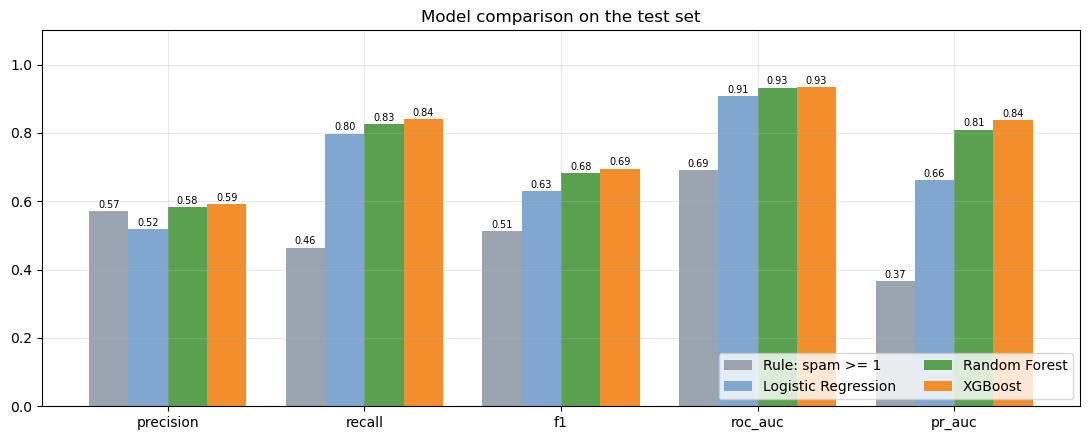

In [13]:
metrics = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
colors = ["#9AA5B1", "#7FA7CF", "#59A14F", "#F28E2B"]

fig, ax = plt.subplots(figsize=(11, 4.5))
width = 0.2
x = np.arange(len(metrics))
for i, (model, row) in enumerate(results_df.iterrows()):
    bars = ax.bar(x + (i - 1.5) * width, row[metrics], width, label=model, color=colors[i])
    ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.1)
ax.set_title("Model comparison on the test set")
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

Confusion matrices show the real counts of correct and wrong calls. A false positive here is an honest receiver flagged as risky, which is the biggest product risk.

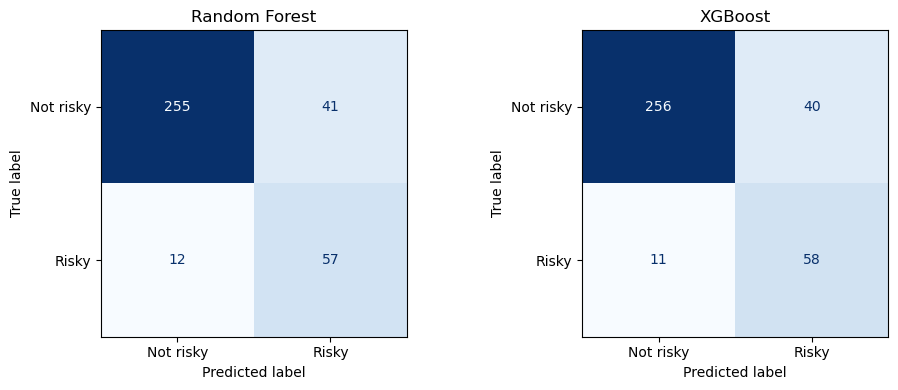

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    pred = (probas[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Not risky", "Risky"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

ROC and precision recall curves for all models. The precision recall curve is the more honest view when risky receivers are rare.

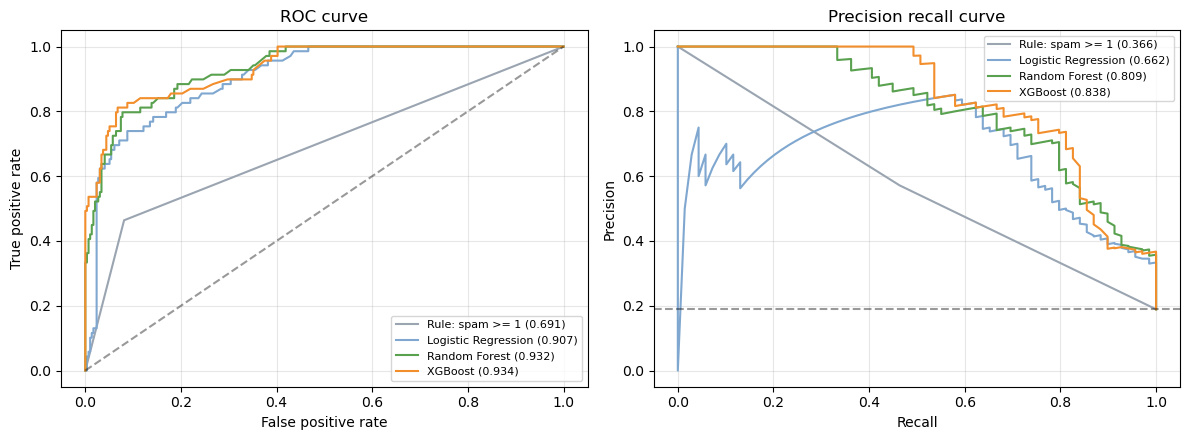

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
curve_colors = {"Rule: spam >= 1": "#9AA5B1", "Logistic Regression": "#7FA7CF",
                "Random Forest": "#59A14F", "XGBoost": "#F28E2B"}

for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({results_df.loc[name, 'roc_auc']:.3f})", color=curve_colors[name])
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} ({results_df.loc[name, 'pr_auc']:.3f})", color=curve_colors[name])

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4)
axes[1].set(title="Precision recall curve", xlabel="Recall", ylabel="Precision")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

Feature importance shows which signals each model relies on. These come from the model itself and are a quick view of what drives the risk score.

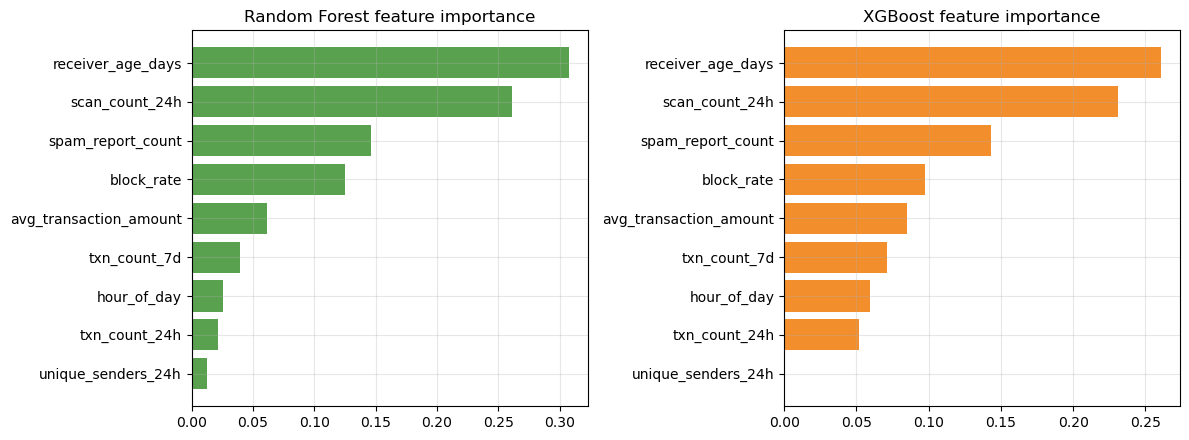

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=False)
for ax, (name, model, color) in zip(axes, [("Random Forest", rf_best, "#59A14F"), ("XGBoost", xgb_best, "#F28E2B")]):
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    ax.barh(imp.index, imp.values, color=color)
    ax.set_title(f"{name} feature importance")
plt.tight_layout()
plt.show()

## 10. Safe, Caution and Risky bands

The app shows a three tier verdict. The thresholds come from the target design: Safe below 0.49, Caution from 0.49 to 0.79, Risky at 0.79 and above. The better of the two models (by PR-AUC) is used, and its bands are compared to the target table.

Model used for the bands: XGBoost
         share  target_share  risky_rate  target_risky_rate
band                                                       
Safe     0.732          0.81       0.041               0.05
Caution  0.137          0.10       0.360               0.30
Risky    0.132          0.09       0.833               0.70


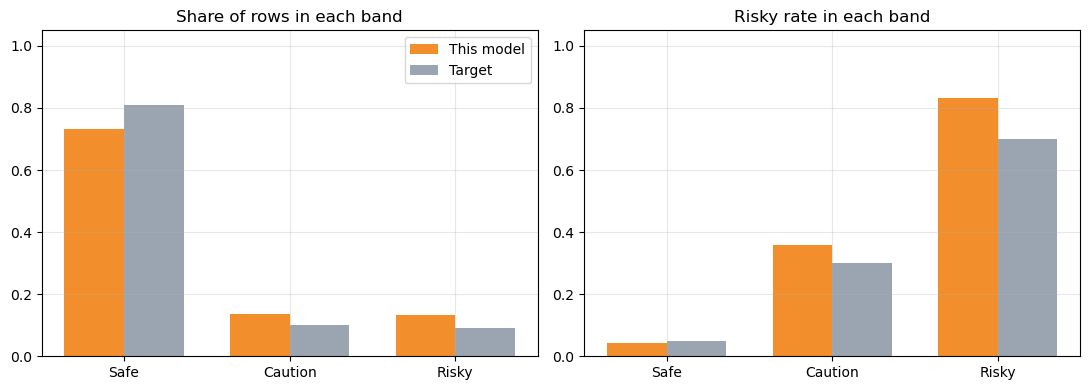

In [17]:
LOW, HIGH = 0.49, 0.79
best_name = results_df.loc[["Random Forest", "XGBoost"], "pr_auc"].idxmax()
print("Model used for the bands:", best_name)

band_df = pd.DataFrame({"proba": probas[best_name], "risky": y_test.values})
band_df["band"] = pd.cut(band_df["proba"], bins=[-0.01, LOW, HIGH, 1.01],
                         labels=["Safe", "Caution", "Risky"], right=False)

summary = band_df.groupby("band", observed=False).agg(
    receivers=("risky", "size"), risky_rate=("risky", "mean")
)
summary["share"] = summary["receivers"] / summary["receivers"].sum()
summary["target_share"] = [0.81, 0.10, 0.09]
summary["target_risky_rate"] = [0.05, 0.30, 0.70]
print(summary[["share", "target_share", "risky_rate", "target_risky_rate"]].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
for ax, actual, target, title in [
    (axes[0], "share", "target_share", "Share of rows in each band"),
    (axes[1], "risky_rate", "target_risky_rate", "Risky rate in each band"),
]:
    ax.bar(x - 0.18, summary[actual], 0.36, label="This model", color="#F28E2B")
    ax.bar(x + 0.18, summary[target], 0.36, label="Target", color="#9AA5B1")
    ax.set_xticks(x)
    ax.set_xticklabels(summary.index)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
axes[0].legend()
plt.tight_layout()
plt.show()

Class weighting pushes probabilities upward, so the Caution and Risky bands can be larger than the target shares. If the bands do not match, adjust `LOW` and `HIGH` using the numbers above and re-run this section.

## 11. Saving the models

Saving both models for the FastAPI inference service, together with the feature order and band thresholds. The feature order matters: the service must send features in exactly this order.

In [18]:
os.makedirs("models", exist_ok=True)

joblib.dump(rf_best, "models/random_forest.joblib")
joblib.dump(xgb_best, "models/xgboost.joblib")
xgb_best.save_model("models/xgboost.json")

metadata = {
    "features": FEATURES,
    "best_model": best_name,
    "bands": {"safe_below": LOW, "risky_from": HIGH},
    "test_metrics": results_df.round(4).to_dict(orient="index"),
}
with open("models/model_info.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved files:", sorted(os.listdir("models")))

Saved files: ['model_info.json', 'random_forest.joblib', 'xgboost.joblib', 'xgboost.json']


Reload the saved models and confirm they give the same predictions as the ones in memory.

In [19]:
rf_loaded = joblib.load("models/random_forest.joblib")
xgb_loaded = joblib.load("models/xgboost.joblib")

print("Random Forest identical:", np.allclose(rf_loaded.predict_proba(X_test)[:, 1], probas["Random Forest"]))
print("XGBoost identical:", np.allclose(xgb_loaded.predict_proba(X_test)[:, 1], probas["XGBoost"]))

Random Forest identical: True
XGBoost identical: True
